In [3]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20190010
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256( f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] py_exp
[学号] 20190010
[机器指纹] 7ab398bfeb57c80a
[RUN_ID] 20190010-7ab398bfeb57c80a


In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
def wigner_density(x):
    if abs(x) <= 2:
        return float(np.sqrt(4 - x**2) / (2 * np.pi))
    return 0.0

In [7]:
def generate_wigner(n):
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError('n must be a positive integer')
    if n <= 0:
        raise ValueError('n must be a positive integer')

    i, j = np.triu_indices(n)
    values = np.random.normal(0, 1 / np.sqrt(n), size=len(i))
    matrix = np.zeros((n, n))
    matrix[i, j] = values
    matrix[j, i] = values
    return matrix

In [8]:
def get_spectrum(matrix):
    return np.sort(np.linalg.eigvalsh(matrix))

In [9]:
print(wigner_density(0), wigner_density(np.int64(1)), wigner_density(np.float64(1)), wigner_density(3))
assert np.isclose(wigner_density(0), 1 / np.pi) and wigner_density(3) == 0.0
Z = generate_wigner(5)
eigenvalues = get_spectrum(Z)
assert Z.shape == (5, 5) and np.allclose(Z, Z.T)
assert len(eigenvalues) == 5 and np.all(eigenvalues[:-1] <= eigenvalues[1:])
assert np.allclose(get_spectrum(np.matrix([[2.0, 1.0], [1.0, 2.0]])), [1.0, 3.0])
for invalid_n in (True, 0, -1, 1.5):
    try:
        generate_wigner(invalid_n)
    except (TypeError, ValueError):
        pass
    else:
        raise AssertionError(f'generate_wigner should reject n={invalid_n!r}')
print('All function tests passed.')

0.3183098861837907 0.27566444771089604 0.27566444771089604 0.0
All function tests passed.


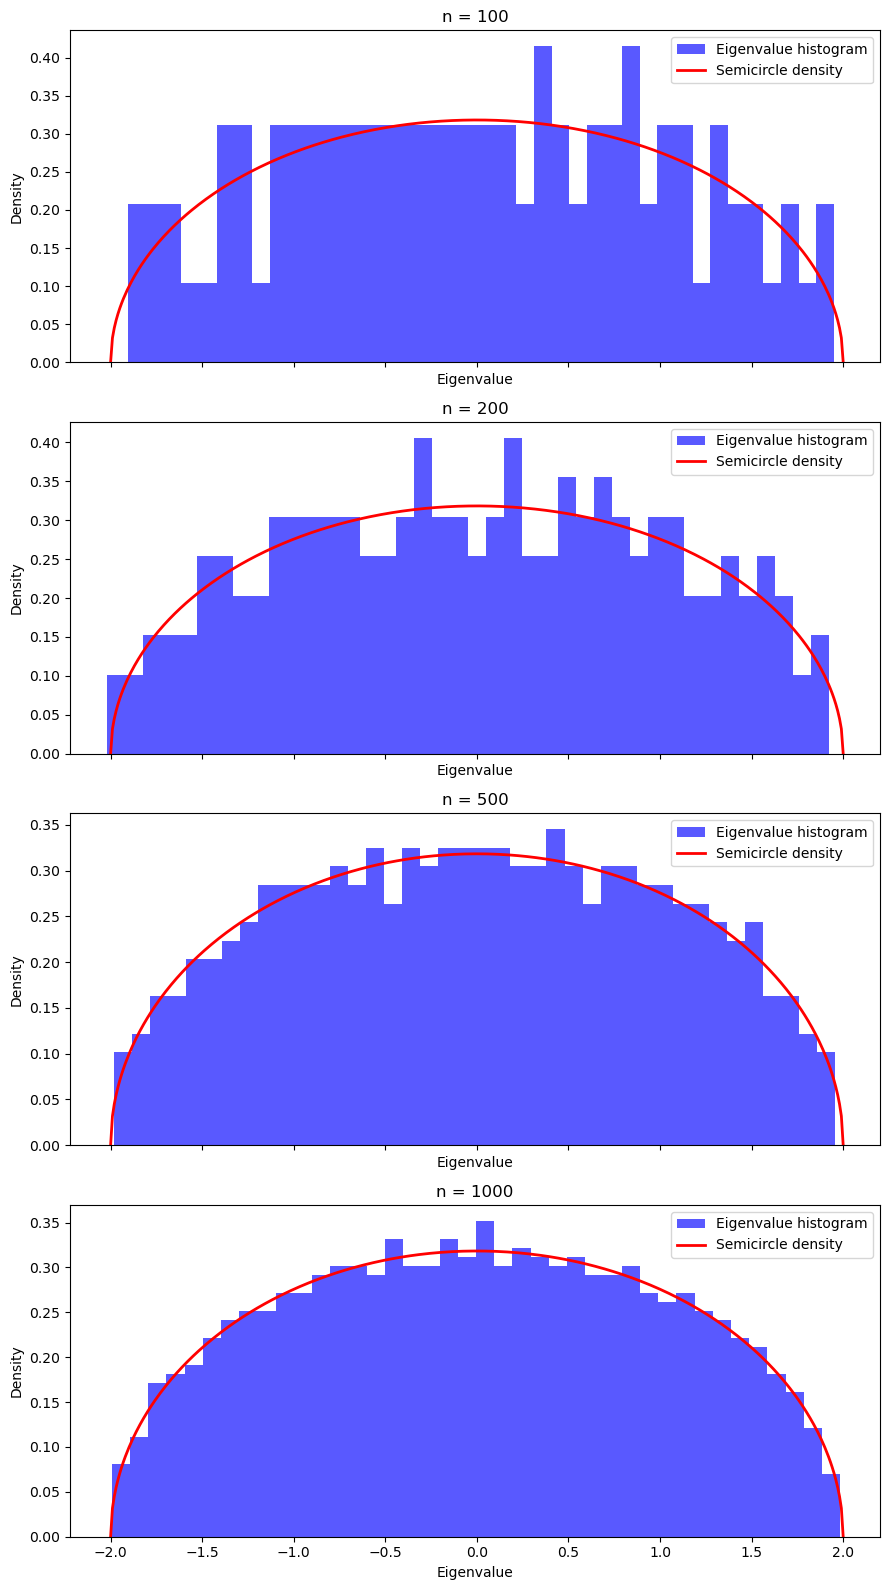

In [10]:
sizes = (100, 200, 500, 1000)
x = np.linspace(-2, 2, 400)
fig, axes = plt.subplots(4, 1, figsize=(9, 16), sharex=True)

for ax, n in zip(axes, sizes):
    eigenvalues = get_spectrum(generate_wigner(n))
    ax.hist(eigenvalues, bins=40, density=True, color='blue', alpha=0.65,
            label='Eigenvalue histogram')
    ax.plot(x, [wigner_density(value) for value in x], color='red',
            linewidth=2, label='Semicircle density')
    ax.set_title(f'n = {n}')
    ax.set_xlabel('Eigenvalue')
    ax.set_ylabel('Density')
    ax.legend()

plt.tight_layout()
plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def is_valid_board(board):
    return bool(
        isinstance(board, np.ndarray)
        and board.ndim == 2
        and np.isin(board, (0, 1)).all()
    )

In [3]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("board must be a 2D NumPy array containing only 0 and 1")

    neighbors = sum(
        np.roll(np.roll(board, dr, axis=0), dc, axis=1)
        for dr in (-1, 0, 1)
        for dc in (-1, 0, 1)
        if (dr, dc) != (0, 0)
    )

    return ((neighbors == 3) | ((board == 1) & (neighbors == 2))).astype(np.uint8)

In [4]:
def draw_gol_board(board):
    if not is_valid_board(board):
        raise ValueError("board must be a 2D NumPy array containing only 0 and 1")

    fig, ax = plt.subplots()
    ax.imshow(board, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    plt.show()
    return fig, ax

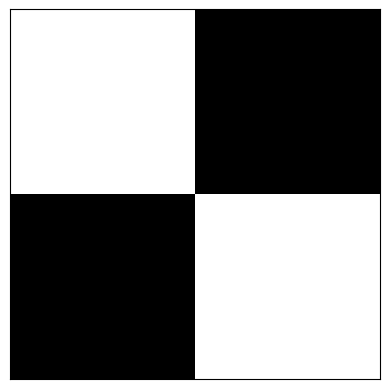

All Game of Life tests passed.


In [5]:
# 有效性检查及无效输入异常
assert is_valid_board(np.array([[0, 1], [1, 0]])) is True

for invalid in ([[0, 1]], np.array([0, 1]), np.array([[0, 2]])):
    assert is_valid_board(invalid) is False
    try:
        gol_step(invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("gol_step should reject invalid input")

# 闪烁器：竖直方向一步后变为水平方向
blinker = np.zeros((5, 5), dtype=int)
blinker[1:4, 2] = 1

expected_blinker = np.zeros((5, 5), dtype=int)
expected_blinker[2, 1:4] = 1
assert np.array_equal(gol_step(blinker), expected_blinker)

# 滑翔机：四步后向右下移动一格
glider = np.zeros((8, 8), dtype=int)
glider[1:4, 1:4] = [[0, 1, 0], [0, 0, 1], [1, 1, 1]]

for _ in range(4):
    glider = gol_step(glider)

expected_glider = np.zeros((8, 8), dtype=int)
expected_glider[2:5, 2:5] = [[0, 1, 0], [0, 0, 1], [1, 1, 1]]
assert np.array_equal(glider, expected_glider)

# 环绕边界：左上角应将右下、右上方向的活细胞计入邻居
wrap_board = np.zeros((4, 4), dtype=int)
wrap_board[3, 3] = wrap_board[3, 1] = wrap_board[1, 3] = 1
assert gol_step(wrap_board)[0, 0] == 1

draw_gol_board(np.array([[0, 1], [1, 0]]))
print("All Game of Life tests passed.")

## 使用 pandas 分析 Iris 数据集



In [21]:
from pathlib import Path
import pandas as pd

search_dirs = [
    Path.cwd(),
    Path.cwd() / "data",
    Path.cwd().parent,
    Path.home() / "Downloads",
    Path.home() / "Documents",
]
candidate_paths = [
    directory / filename
    for directory in search_dirs
    for filename in ("iris.csv", "Iris.csv")
]
csv_path = next((path for path in candidate_paths if path.is_file()), None)
if csv_path is None:
    tried = "\n".join(str(path) for path in candidate_paths)
    raise FileNotFoundError(
        f"找不到 iris.csv。已检查以下路径：\n{tried}\n"
        "请将文件放在 Notebook 当前目录或常见数据目录中。"
    )

df = pd.read_csv(csv_path)
required_columns = {
    "SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"CSV 缺少必需列：{sorted(missing_columns)}")

print(f"数据文件：{csv_path}")
print(f"数据点（行数）：{len(df)}")
print("列名：", list(df.columns))
print("各列数据类型：")
print(df.dtypes)
flower_types = df["Species"].dropna().unique().tolist()
print(f"花卉种类数：{df['Species'].nunique()}")
print("花卉种类：", flower_types)

数据文件：c:\Users\袁苹峰\Desktop\Python\03\iris.csv
数据点（行数）：150
列名： ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
各列数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object
花卉种类数：3
花卉种类： ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']


### 数据概览

本数据集包含 150 个数据点和 3 种花卉。列名为 `Id`、`SepalLengthCm`、`SepalWidthCm`、`PetalLengthCm`、`PetalWidthCm`、`Species`；其中 `Id` 是记录编号，四个 `...Cm` 列分别是萼片长度、萼片宽度、花瓣长度和花瓣宽度，`Species` 是花卉种类。运行上一个单元格可查看每列实际数据类型和花卉种类。

In [22]:
if len(df) <= 37:
    raise ValueError("数据不足 38 行，无法修改指定行。")

measurement_and_species = [
    "SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"
]
df.loc[34, measurement_and_species] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37, measurement_and_species] = [4.9, 3.6, 1.4, 0.1, "setosa"]
display(df.iloc[[34, 37]])

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
34,35,4.9,3.1,1.5,0.2,setosa
37,38,4.9,3.6,1.4,0.1,setosa


In [23]:
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]
display(df[["Petal.Ratio", "Sepal.Ratio"]].head())

,Petal.Ratio,Sepal.Ratio
0,7.0,1.457143
1,7.0,1.633333
2,6.5,1.468750
3,7.5,1.483871
4,7.0,1.388889


In [24]:
output_path = csv_path.with_name("iris_corrected.csv")
df.to_csv(output_path, index=False)
print(f"已保存：{output_path}")

已保存：c:\Users\袁苹峰\Desktop\Python\03\iris_corrected.csv


### 分组统计

按 `Species` 分组，一次计算两个比例特征的均值、中位数、最小值、最大值和标准差。题目要求将两行的标签精确改为 `setosa`；原文件标签是 `Iris-setosa`，因此统计结果会将 `setosa` 与 `Iris-setosa` 显示为两个标签。

In [25]:
ratio_stats = (
    df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]]
    .agg(["mean", "median", "min", "max", "std"])
)
display(ratio_stats)

Petal.Ratio                                      Sepal.Ratio  \
                       mean     median       min   max       std        mean   
Species                                                                        
Iris-setosa        6.747917   7.000000  2.666667  15.0  2.718713    1.470159   
Iris-versicolor    3.242837   3.240385  2.666667   4.1  0.312456    2.160402   
Iris-virginica     2.780662   2.666667  2.125000   4.0  0.407367    2.230453   
setosa            10.750000  10.750000  7.500000  14.0  4.596194    1.470878   

                                                         
                   median       min       max       std  
Species                                                  
Iris-setosa      1.463063  1.268293  1.956522  0.119117  
Iris-versicolor  2.161290  1.764706  2.818182  0.228658  
Iris-virginica   2.169540  1.823529  2.961538  0.246992  
setosa           1.470878  1.361111  1.580645  0.155234